<a href="https://colab.research.google.com/github/OleksandrKolesnichenko/DTA-Python-2026/blob/main/%D0%92%D0%B5%D0%BA%D1%82%D0%BE%D1%80%D0%B8_%D0%BC%D0%B0%D1%82%D1%80%D0%B8%D1%86%D1%96_%D0%BB%D0%B5%D0%BA%D1%86%D1%96%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧮 Вектори й матриці в Python

**Заняття: основні поняття та операції з векторами й матрицями**

Тривалість: **90 хвилин** · Інструменти: `numpy`, `pandas`, `matplotlib`

| # | Тема | Час |
|---|---|---|
| 0 | Вступ: навіщо аналітику лінійна алгебра | 3 хв |
| 1 | Вектор як набір даних | 10 хв |
| 2 | Матриця як таблиця | 10 хв |
| 3 | Розмірність | 7 хв |
| 4 | Довжина (норма) вектора і відстань | 10 хв |
| 5 | Особливі матриці | 8 хв |
| 6 | Додавання і множення на скаляр | 10 хв |
| 7 | Скалярний добуток | 12 хв |
| 8 | Множення матриць | 12 хв |
| 9 | Транспонування | 5 хв |
| 10 | Підсумок | 3 хв |
| ✍️ | Перевірте себе (домашнє завдання) | — |

> 💡 Ноутбук можна відкрити в **Google Colab**: *File → Upload notebook*. Усі дані — всередині ноутбука.

---
## 0. Вступ (⏱ 3 хв)

Слова «вектор» і «матриця» звучать як шкільна математика. Але ви вже **щодня** з ними працюєте:

- **Рядок таблиці** (один клієнт з віком, кількістю покупок і середнім чеком) — це **вектор**.
- **Уся таблиця** (Excel, SQL-запит, DataFrame) — це **матриця**.
- **«Помножити кількість на ціну й скласти»** — це **скалярний добуток**.
- **«Порахувати суму кожного замовлення»** для тисячі замовлень одразу — це **множення матриці на вектор**.

На цьому побудовані рекомендаційні системи («схожі клієнти купують…»), машинне навчання і майже вся сучасна аналітика. Сьогодні розберемося з основами на простих прикладах.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (6, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
np.set_printoptions(suppress=True)   # показувати числа без «e+02»

# Допоміжна функція: малює вектори-стрілки з початку координат
def draw_vectors(vectors, colors, labels, lim=6):
    fig, ax = plt.subplots()
    for v, c, l in zip(vectors, colors, labels):
        ax.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=1, color=c, width=0.012, label=l)
    ax.set_xlim(-1, lim)
    ax.set_ylim(-1, lim)
    ax.set_aspect('equal')
    ax.axhline(0, color='gray', linewidth=0.8)
    ax.axvline(0, color='gray', linewidth=0.8)
    ax.legend()
    return ax

---
## 1. Вектор як набір даних (⏱ 10 хв)

**Вектор** — це **упорядкований набір чисел**. «Упорядкований» означає, що кожна позиція має свій зміст, і переставляти числа не можна.

| Приклад | Вектор | Що означає кожна позиція |
|---|---|---|
| Профіль клієнта | (29, 12, 450, 7) | вік, кількість покупок, середній чек, днів з останньої покупки |
| Продажі за тиждень | (12, 15, 9, 20, 18, 25, 30) | понеділок, вівторок, …, неділя |
| Точка на площині | (3, 2) | x, y |

**Позначення:** вектори пишуть маленькою жирною літерою або зі стрілкою: **a** = (a₁, a₂, …, aₙ). Числа a₁, a₂, … називають **координатами** або **компонентами** вектора.

**Дві «точки зору» на вектор:**
1. **Аналітична** — це просто рядок даних про один об'єкт.
2. **Геометрична** — це **стрілка** з початку координат у точку. Для 2 чисел її можна намалювати на площині; для 100 чисел — ні, але всі правила працюють так само.

У Python вектор — це масив `numpy`: `np.array([...])`.

In [ ]:
# Профіль клієнта: вік, кількість покупок, середній чек, днів з останньої покупки
client = np.array([29, 12, 450, 7])
print('Клієнт:', client)
print('Середній чек (позиція з індексом 2):', client[2])   # індекси в Python з 0

Клієнт: [ 29  12 450   7]
Середній чек (позиція з індексом 2): 450


In [ ]:
# Продажі кав'ярні за тиждень
week = np.array([12, 15, 9, 20, 18, 25, 30])
days = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Нд']

print('Продажі:', week)
print('Неділя:', week[-1])          # -1 — останній елемент
print('Вихідні:', week[5:])         # зріз з індексу 5 до кінця
print('Усього за тиждень:', week.sum())

Продажі: [12 15  9 20 18 25 30]
Неділя: 30
Вихідні: [25 30]
Усього за тиждень: 129


👀 **Чому не звичайний список Python?** Зі списком `[12, 15, 9]` не можна просто сказати «помнож усе на 2» чи «додай інший тиждень». Масив `numpy` робить ці операції одразу з усіма елементами — і в сотні разів швидше на великих даних.

In [ ]:
lst = [12, 15, 9]
arr = np.array([12, 15, 9])

print('Список × 2:', lst * 2)    # список просто повторюється двічі!
print('Масив × 2: ', arr * 2)    # кожен елемент множиться на 2

Список × 2: [12, 15, 9, 12, 15, 9]
Масив × 2:  [24 30 18]


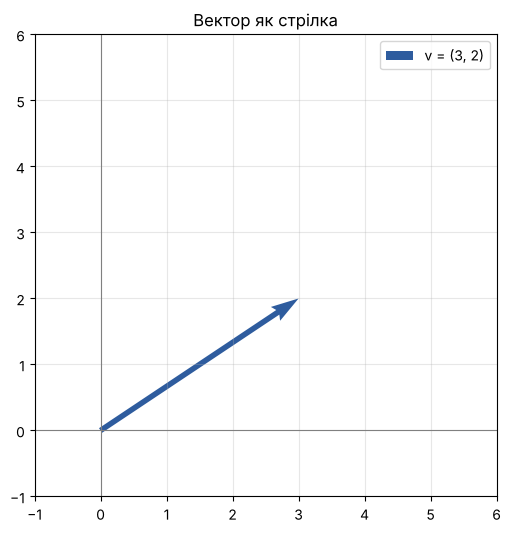

In [ ]:
# Геометрична точка зору: вектор (3, 2) — стрілка в точку x=3, y=2
v = np.array([3, 2])
ax = draw_vectors([v], ['#2E5C9E'], ['v = (3, 2)'])
ax.set_title('Вектор як стрілка')
plt.show()

---
## 2. Матриця як таблиця (⏱ 10 хв)

**Матриця** — це **прямокутна таблиця чисел** з рядками і стовпцями.

У даних майже завжди:
- **рядок = один об'єкт** (клієнт, замовлення, день);
- **стовпець = одна ознака** (вік, сума, кількість).

Тобто **кожен рядок матриці — вектор одного об'єкта**, а вся матриця — це вектори, складені один під одним.

**Позначення:** матриці пишуть великою літерою: A. Елемент у рядку i і стовпці j позначають $a_{ij}$.

$$A = \begin{pmatrix} a_{11} & a_{12} & a_{13} \\ a_{21} & a_{22} & a_{23} \end{pmatrix}$$

> ⚠️ У математиці рядки і стовпці нумерують **з 1**, а в Python — **з 0**. Елемент $a_{23}$ у Python — це `A[1, 2]`.

In [ ]:
# Таблиця клієнтів — звичайний DataFrame
clients = pd.DataFrame({
    'age':        [29, 41, 35, 23, 52],
    'purchases':  [12, 3, 25, 8, 15],
    'avg_check':  [450, 1200, 380, 300, 900],
    'days_since': [7, 60, 2, 14, 30],
}, index=['Олена', 'Петро', 'Марія', 'Іван', 'Ганна'])
clients

,age,purchases,avg_check,days_since
Олена,29,12,450,7
Петро,41,3,1200,60
Марія,35,25,380,2
Іван,23,8,300,14
Ганна,52,15,900,30


In [ ]:
# Та сама таблиця як матриця numpy: лише числа, без назв
X = clients.to_numpy()
print(X)

[[  29   12  450    7]
 [  41    3 1200   60]
 [  35   25  380    2]
 [  23    8  300   14]
 [  52   15  900   30]]


In [ ]:
print('Рядок 0 (Олена):           ', X[0])        # вектор одного клієнта
print('Стовпець 2 (середній чек): ', X[:, 2])     # двокрапка = «усі рядки»
print('Елемент [1, 2] (чек Петра):', X[1, 2])

Рядок 0 (Олена):            [ 29  12 450   7]
Стовпець 2 (середній чек):  [ 450 1200  380  300  900]
Елемент [1, 2] (чек Петра): 1200


**Як читати `X[:, 2]`:** до коми — рядки, після коми — стовпці. `:` означає «всі». Тобто «всі рядки, стовпець 2».

---
## 3. Розмірність (⏱ 7 хв)

**Розмірність вектора** — кількість чисел у ньому. Вектор клієнта (29, 12, 450, 7) — **чотиривимірний**.

**Розмір матриці** записують як **«рядки × стовпці»**. Матриця з 5 клієнтами і 4 ознаками має розмір **5 × 4**.

| Атрибут numpy | Що показує | Для X (5 × 4) |
|---|---|---|
| `.shape` | форму: (рядки, стовпці) | (5, 4) |
| `.ndim` | кількість «осей»: 1 — вектор, 2 — матриця | 2 |
| `.size` | загальна кількість чисел | 20 |

Розмірність потрібно постійно контролювати: більшість помилок з векторами і матрицями — це **«розміри не збігаються»**.

In [ ]:
print('client: shape =', client.shape, '| ndim =', client.ndim, '| size =', client.size)
print('X:      shape =', X.shape, '| ndim =', X.ndim, '| size =', X.size)

client: shape = (4,) | ndim = 1 | size = 4
X:      shape = (5, 4) | ndim = 2 | size = 20


### Вектор-рядок і вектор-стовпець

У математиці вектор можна записати **рядком** (1 × n) або **стовпцем** (n × 1). Для простих операцій у `numpy` різниці немає, але інколи (наприклад, у множенні матриць) вона важлива. Змінити форму можна методом `.reshape()`:

In [ ]:
a = np.array([1, 2, 3])
row = a.reshape(1, 3)     # 1 рядок, 3 стовпці
col = a.reshape(3, 1)     # 3 рядки, 1 стовпець

print('Звичайний вектор:', a.shape)
print('Вектор-рядок:', row.shape)
print(row)
print('Вектор-стовпець:', col.shape)
print(col)

Звичайний вектор: (3,)
Вектор-рядок: (1, 3)
[[1 2 3]]
Вектор-стовпець: (3, 1)
[[1]
 [2]
 [3]]


---
## 4. Довжина (норма) вектора і відстань (⏱ 10 хв)

**Довжина вектора** (її ще називають **нормою**) — це довжина стрілки. Позначають $\|\mathbf{v}\|$.

Для вектора (3, 4) це **теорема Піфагора**: стрілка — гіпотенуза трикутника з катетами 3 і 4:

$$\|(3, 4)\| = \sqrt{3^2 + 4^2} = \sqrt{25} = 5$$

Для вектора з n чисел формула та сама:

$$\|\mathbf{v}\| = \sqrt{v_1^2 + v_2^2 + \dots + v_n^2}$$

**Відстань між двома векторами** — це довжина їхньої **різниці**: $\|\mathbf{a} - \mathbf{b}\|$. Що менша відстань, то більше схожі об'єкти. Саме так працюють алгоритми «знайди схожих клієнтів».

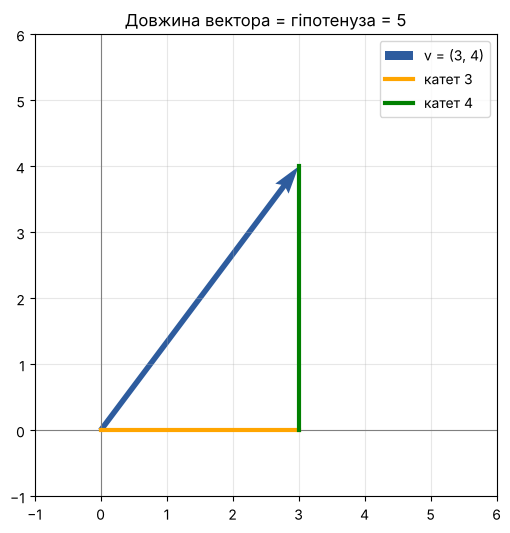

In [ ]:
v = np.array([3, 4])
ax = draw_vectors([v], ['#2E5C9E'], ['v = (3, 4)'])
ax.plot([0, 3], [0, 0], color='orange', linewidth=3, label='катет 3')
ax.plot([3, 3], [0, 4], color='green', linewidth=3, label='катет 4')
ax.legend()
ax.set_title('Довжина вектора = гіпотенуза = 5')
plt.show()

In [ ]:
# Довжина вручну і через numpy
norm_manual = np.sqrt((v ** 2).sum())   # підносимо до квадрата, складаємо, беремо корінь
norm_np = np.linalg.norm(v)

print('Вручну:         ', norm_manual)
print('np.linalg.norm: ', norm_np)

Вручну:          5.0
np.linalg.norm:  5.0


In [ ]:
# Відстань між клієнтами: хто найбільше схожий на Олену?
olena = X[0]
for name, row in zip(clients.index, X):
    print(f'{name:6}: відстань до Олени = {np.linalg.norm(olena - row):8.1f}')

Олена : відстань до Олени =      0.0
Петро : відстань до Олени =    752.0
Марія : відстань до Олени =     71.6
Іван  : відстань до Олени =    150.3
Ганна : відстань до Олени =    451.2


⚠️ **Пастка масштабу.** Відстань вийшла майже повністю «про середній чек»: чек вимірюється сотнями гривень, а вік — десятками років. Різниця в чеку на 500 грн «перекриває» будь-яку різницю у віці.

Тому перед порівнянням об'єктів ознаки **приводять до одного масштабу**. Найпростіше — **стандартизація** (z-оцінка з минулих занять): від кожного стовпця віднімаємо його середнє і ділимо на стандартне відхилення.

In [ ]:
X_std = (X - X.mean(axis=0)) / X.std(axis=0)    # axis=0 — рахуємо по кожному стовпцю окремо

for name, row in zip(clients.index, X_std):
    print(f'{name:6}: відстань до Олени (стандартизовано) = {np.linalg.norm(X_std[0] - row):.2f}')

Олена : відстань до Олени (стандартизовано) = 0.00
Петро : відстань до Олени (стандартизовано) = 3.74
Марія : відстань до Олени (стандартизовано) = 1.88
Іван  : відстань до Олени (стандартизовано) = 0.98
Ганна : відстань до Олени (стандартизовано) = 2.89


Тепер усі чотири ознаки важать однаково, і результат змінився: **без стандартизації** найближчою до Олени була Марія (бо в неї схожий чек), а **після** — Іван, який схожий на Олену одразу за кількома ознаками: молодий, з невеликим чеком і нещодавньою покупкою.

### Одиничний вектор

Якщо поділити вектор на його довжину, вийде вектор **довжиною 1**, що дивиться в той самий бік. Це називають **нормуванням**. Воно знадобиться в розділі 7.

In [ ]:
unit = v / np.linalg.norm(v)
print('Одиничний вектор:', unit, '| довжина:', np.linalg.norm(unit))

Одиничний вектор: [0.6 0.8] | довжина: 1.0


---
## 5. Особливі матриці (⏱ 8 хв)

| Матриця | Як виглядає | numpy | Навіщо |
|---|---|---|---|
| **Квадратна** | рядків стільки ж, скільки стовпців (n × n) | — | лише для квадратних визначені одинична, діагональна тощо |
| **Нульова** | усі елементи 0 | `np.zeros((m, n))` | «порожня» заготовка для результатів |
| **Одинична** I | 1 на головній діагоналі, решта 0 | `np.eye(n)` | працює як «1» для матриць: A · I = A |
| **Діагональна** | числа лише на діагоналі, решта 0 | `np.diag([...])` | множення на неї **масштабує** кожен стовпець окремо |
| **Симетрична** | A = Aᵀ (дзеркальна відносно діагоналі) | — | кореляційна матриця з минулого заняття — симетрична! |

**Головна діагональ** — елементи $a_{11}, a_{22}, a_{33}, \dots$, тобто з лівого верхнього кута в правий нижній.

In [ ]:
print('Нульова 2 × 3:')
print(np.zeros((2, 3)))
print('\nОдинична 4 × 4:')
print(np.eye(4))

Нульова 2 × 3:
[[0. 0. 0.]
 [0. 0. 0.]]

Одинична 4 × 4:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


In [ ]:
D = np.diag([2, 5, 10])
print('Діагональна матриця:')
print(D)

M = np.array([[1, 2, 3],
              [4, 5, 6],
              [7, 8, 9]])
print('\nДіагональ іншої матриці:', np.diag(M))   # np.diag від матриці — дістає діагональ

Діагональна матриця:
[[ 2  0  0]
 [ 0  5  0]
 [ 0  0 10]]

Діагональ іншої матриці: [1 5 9]


In [ ]:
# Кореляційна матриця симетрична: corr(A, B) = corr(B, A)
corr = clients.corr().to_numpy()
print(np.round(corr, 2))
print('\nСиметрична?', np.allclose(corr, corr.T))   # .T — транспонування (розділ 9)

[[ 1.    0.11  0.75  0.52]
 [ 0.11  1.   -0.49 -0.71]
 [ 0.75 -0.49  1.    0.94]
 [ 0.52 -0.71  0.94  1.  ]]

Симетрична? True


---
## 6. Додавання і множення на скаляр (⏱ 10 хв)

### Додавання

Вектори (і матриці) **однакового розміру** додаються **поелементно**: перше з першим, друге з другим…

$$(1, 2, 3) + (10, 20, 30) = (11, 22, 33)$$

**Приклад:** продажі першого тижня + продажі другого тижня = продажі за два тижні **по кожному дню**.

### Множення на скаляр

**Скаляр** — це просто одне число. Множення на скаляр множить **кожен** елемент:

$$2 \cdot (1, 2, 3) = (2, 4, 6)$$

**Приклад:** ціни зросли на 10% → новий вектор цін = 1.1 × старий.

> ⚠️ Вектори **різної довжини** додавати не можна: незрозуміло, що з чим додавати. numpy видасть помилку.

In [ ]:
week1 = np.array([12, 15, 9, 20, 18, 25, 30])
week2 = np.array([14, 13, 11, 22, 21, 28, 27])

print('Тиждень 1:   ', week1)
print('Тиждень 2:   ', week2)
print('Сума:        ', week1 + week2)
print('Різниця 2−1: ', week2 - week1)      # віднімання — те саме, що додавання з «мінусом»

Тиждень 1:    [12 15  9 20 18 25 30]
Тиждень 2:    [14 13 11 22 21 28 27]
Сума:         [26 28 20 42 39 53 57]
Різниця 2−1:  [ 2 -2  2  2  3  3 -3]


In [ ]:
prices = np.array([45, 30, 60])          # кава, чай, круасан
print('Старі ціни:  ', prices)
print('+10%:        ', prices * 1.1)
print('Знижка 20%:  ', prices * 0.8)

Старі ціни:   [45 30 60]
+10%:         [49.5 33.  66. ]
Знижка 20%:   [36. 24. 48.]


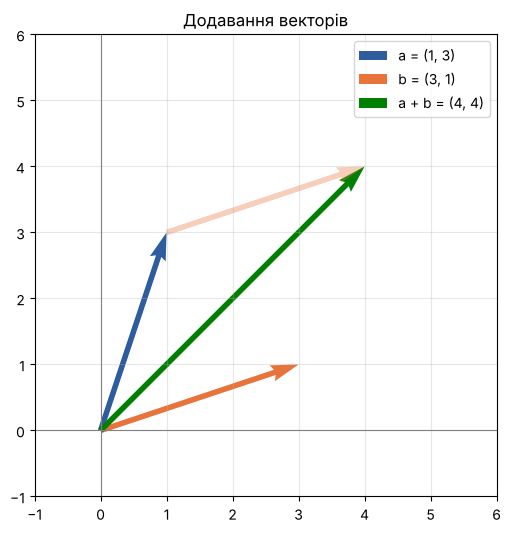

In [ ]:
# Геометрично: додавання — «прикласти стрілку до кінця іншої»
a = np.array([1, 3])
b = np.array([3, 1])
ax = draw_vectors([a, b, a + b], ['#2E5C9E', '#E8743B', 'green'], ['a = (1, 3)', 'b = (3, 1)', 'a + b = (4, 4)'])
ax.quiver(a[0], a[1], b[0], b[1], angles='xy', scale_units='xy', scale=1, color='#E8743B', alpha=0.35, width=0.012)
ax.set_title('Додавання векторів')
plt.show()

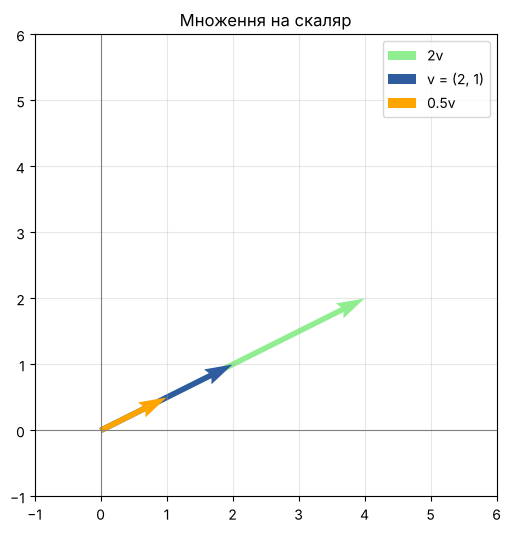

In [ ]:
# Множення на скаляр: стрілка розтягується (або стискається, або розвертається)
v = np.array([2, 1])
ax = draw_vectors([2 * v, v, 0.5 * v], ['lightgreen', '#2E5C9E', 'orange'], ['2v', 'v = (2, 1)', '0.5v'])
ax.set_title('Множення на скаляр')
plt.show()

In [ ]:
# Матриці додаються так само. Залишки товару в 2 магазинах (рядки) по 3 товарах (стовпці)
stock    = np.array([[50, 20, 30],
                     [40, 35, 10]])
delivery = np.array([[10, 0, 20],
                     [ 5, 5, 15]])
print('Після поставки:')
print(stock + delivery)

Після поставки:
[[60 20 50]
 [45 40 25]]


In [ ]:
# Що буде, якщо розміри не збігаються?
try:
    np.array([1, 2, 3]) + np.array([1, 2])
except ValueError as e:
    print('Помилка:', e)

Помилка: operands could not be broadcast together with shapes (3,) (2,) 


---
## 7. Скалярний добуток (⏱ 12 хв)

**Скалярний добуток** двох векторів однакової довжини: перемножуємо **попарно** і **складаємо**. Результат — **одне число** (скаляр, звідси й назва).

$$\mathbf{a} \cdot \mathbf{b} = a_1 b_1 + a_2 b_2 + \dots + a_n b_n$$

**Найважливіший приклад для аналітика — чек:**
- кількість у кошику: (2 кави, 1 чай, 3 круасани) = (2, 1, 3)
- ціни: (45, 30, 60)
- сума = 2·45 + 1·30 + 3·60 = **300 грн** — це і є скалярний добуток!

**Ще приклади:** зважений середній бал (оцінки · ваги), виручка (кількості · ціни), будь-яка «зважена сума».

| Код | Що робить |
|---|---|
| `(a * b).sum()` | вручну: поелементний добуток і сума |
| `np.dot(a, b)` | скалярний добуток |
| `a @ b` | те саме, коротко |

In [ ]:
qty = np.array([2, 1, 3])          # 2 кави, 1 чай, 3 круасани
prices = np.array([45, 30, 60])

print('Поелементний добуток:', qty * prices)          # 90, 30, 180
print('Сума вручну:', (qty * prices).sum())
print('np.dot:     ', np.dot(qty, prices))
print('Через @:    ', qty @ prices)

Поелементний добуток: [ 90  30 180]
Сума вручну: 300
np.dot:      300
Через @:     300


In [ ]:
# Зважений бал студента: оцінки за 4 частини курсу і їхня вага
grades = np.array([80, 65, 90, 70])          # тести, домашні, проєкт, іспит
weights = np.array([0.2, 0.2, 0.3, 0.3])     # ваги в сумі дають 1

print('Звичайне середнє:', grades.mean())
print('Зважений бал:    ', grades @ weights)

Звичайне середнє: 76.25
Зважений бал:     77.0


### Геометричний зміст: кут між векторами

Скалярний добуток пов'язаний з **кутом** між стрілками:

$$\mathbf{a} \cdot \mathbf{b} = \|\mathbf{a}\| \cdot \|\mathbf{b}\| \cdot \cos(\text{кут})$$

Звідси **косинусна схожість** — одна з найпопулярніших мір у рекомендаційних системах і в аналізі текстів:

$$\cos = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\| \cdot \|\mathbf{b}\|}$$

| cos | Кут | Зміст |
|---|---|---|
| 1 | 0° | вектори дивляться в один бік — дуже схожі |
| 0 | 90° | **перпендикулярні** (ортогональні) — нічого спільного |
| −1 | 180° | протилежні |

In [ ]:
# Оцінки 5 фільмів від трьох користувачів (1–5)
films = ['Бойовик', 'Комедія', 'Драма', 'Жахи', 'Мультфільм']
anna  = np.array([5, 4, 1, 5, 2])
bohdan = np.array([4, 5, 2, 4, 1])
olha  = np.array([1, 2, 5, 1, 5])

def cosine(a, b):
    return (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))

print(f'Анна і Богдан: {cosine(anna, bohdan):.2f}')
print(f'Анна і Ольга:  {cosine(anna, olha):.2f}')

Анна і Богдан: 0.96
Анна і Ольга:  0.52


Смаки Анни й Богдана дуже схожі (0.96), а Ольги — значно менше (0.52). Тому Анні варто рекомендувати те, що сподобалось **Богдану**.

Чому в Ольги не 0 і не мінус? Усі оцінки додатні (від 1 до 5), тож стрілки завжди дивляться «в один квадрант», і косинус додатний. Тому тут порівнюють значення **між собою**: 0.96 — набагато ближче, ніж 0.52.

a · b = 0


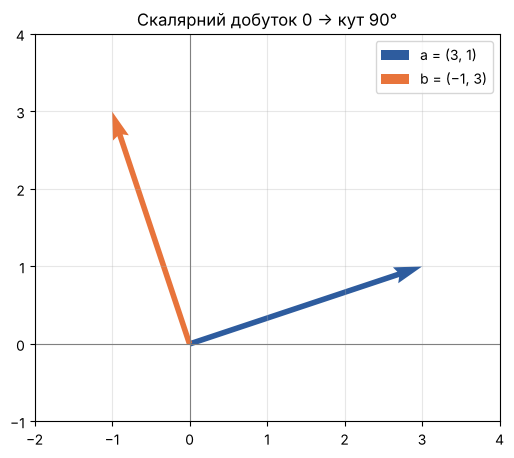

In [ ]:
# Перпендикулярні вектори: скалярний добуток = 0
a = np.array([3, 1])
b = np.array([-1, 3])
print('a · b =', a @ b)
ax = draw_vectors([a, b], ['#2E5C9E', '#E8743B'], ['a = (3, 1)', 'b = (−1, 3)'], lim=4)
ax.set_xlim(-2, 4)
ax.set_title('Скалярний добуток 0 → кут 90°')
plt.show()

---
## 8. Множення матриць (⏱ 12 хв)

### Матриця × вектор

Уявіть 4 замовлення (рядки) і 3 товари (стовпці). Щоб знайти суму **кожного** замовлення, треба кожен рядок скалярно помножити на вектор цін. Це і є **множення матриці на вектор**: результат — вектор із 4 сум.

### Матриця × матриця

**Правило «рядок на стовпець»:** елемент результату в рядку i і стовпці j — це **скалярний добуток i-го рядка першої матриці на j-й стовпець другої**.

$$C_{ij} = A_{i1} B_{1j} + A_{i2} B_{2j} + \dots + A_{in} B_{nj}$$

### Правило розмірів

$$\underbrace{(m \times \mathbf{n})}_{A} \cdot \underbrace{(\mathbf{n} \times p)}_{B} = \underbrace{(m \times p)}_{C}$$

- **Внутрішні** числа мають **збігатися** (кількість стовпців A = кількість рядків B).
- **Зовнішні** дають розмір результату.

> ⚠️ **Порядок важливий:** у загальному випадку A · B ≠ B · A. А часто B · A взагалі неможливо порахувати через розміри.

> ⚠️ **`*` ≠ `@`!** У numpy `A * B` — **поелементне** множення (вимагає однакових розмірів), а `A @ B` — **матричне**. Це найчастіша помилка новачків.

In [ ]:
# 4 замовлення × 3 товари (кава, чай, круасан)
orders = np.array([[2, 1, 3],
                   [1, 0, 0],
                   [0, 2, 2],
                   [3, 3, 1]])
prices = np.array([45, 30, 60])

totals = orders @ prices
print('Розмір:', orders.shape, '@', prices.shape, '→', totals.shape)
print('Сума кожного замовлення:', totals)

Розмір: (4, 3) @ (3,) → (4,)
Сума кожного замовлення: [300  45 180 285]


In [ ]:
# Як це порахувалося: кожен рядок · ціни
for i, row in enumerate(orders):
    parts = ' + '.join(f'{q}·{p}' for q, p in zip(row, prices))
    print(f'Замовлення {i}: {parts} = {row @ prices}')

Замовлення 0: 2·45 + 1·30 + 3·60 = 300
Замовлення 1: 1·45 + 0·30 + 0·60 = 45
Замовлення 2: 0·45 + 2·30 + 2·60 = 180
Замовлення 3: 3·45 + 3·30 + 1·60 = 285


In [ ]:
# Матриця × матриця: 3 магазини × 4 товари (продано штук)
sold = np.array([[120,  80, 60, 30],
                 [ 90, 110, 40, 50],
                 [150,  60, 70, 20]])

# 4 товари × 2 показники: ціна продажу і собівартість
price_cost = np.array([[45, 15],
                       [30,  8],
                       [60, 25],
                       [80, 40]])

result = sold @ price_cost
print('Розмір:', sold.shape, '@', price_cost.shape, '→', result.shape)
pd.DataFrame(result, index=['Магазин 1', 'Магазин 2', 'Магазин 3'], columns=['Виручка', 'Собівартість'])

Розмір: (3, 4) @ (4, 2) → (3, 2)


,Виручка,Собівартість
Магазин 1,13800,5140
Магазин 2,13750,5230
Магазин 3,14350,5280


Одна операція `@` порахувала виручку і собівартість для **всіх магазинів одразу**. У реальних даних замість 3 × 4 там можуть бути 10 000 × 500 — і код той самий.

Розберемо одну клітинку вручну: **виручка магазину 1** = рядок 1 матриці `sold` · стовпець «ціна»:

In [ ]:
row_store1 = sold[0]           # (120, 80, 60, 30)
col_price = price_cost[:, 0]   # (45, 30, 60, 80)
print('120·45 + 80·30 + 60·60 + 30·80 =', row_store1 @ col_price)

120·45 + 80·30 + 60·60 + 30·80 = 13800


In [ ]:
# Множення матриць вручну через цикли — щоб побачити правило «рядок на стовпець»
def matmul_manual(A, B):
    m, n = A.shape
    n2, p = B.shape
    assert n == n2, 'Кількість стовпців A має дорівнювати кількості рядків B'
    C = np.zeros((m, p))
    for i in range(m):
        for j in range(p):
            C[i, j] = A[i] @ B[:, j]      # рядок i на стовпець j
    return C

print('Вручну дорівнює @?', np.allclose(matmul_manual(sold, price_cost), sold @ price_cost))

Вручну дорівнює @? True


In [ ]:
# Порядок важливий: A @ B ≠ B @ A
A = np.array([[1, 2],
              [3, 4]])
B = np.array([[0, 1],
              [1, 0]])
print('A @ B =\n', A @ B)
print('B @ A =\n', B @ A)

A @ B =
 [[2 1]
 [4 3]]
B @ A =
 [[3 4]
 [1 2]]


In [ ]:
# * проти @
print('A * B (поелементно) =\n', A * B)
print('A @ B (матрично) =\n', A @ B)

A * B (поелементно) =
 [[0 2]
 [3 0]]
A @ B (матрично) =
 [[2 1]
 [4 3]]


In [ ]:
# Особливі матриці в дії
I = np.eye(2)
print('A @ I = A?', np.allclose(A @ I, A))       # одинична — як «помножити на 1»

# Діагональна матриця масштабує стовпці: знижки 10% на каву, 0% на чай, 50% на круасани
discount = np.diag([0.9, 1.0, 0.5])
print('\nКількості × знижки (масштабуємо кожен стовпець):')
print(orders @ discount)

A @ I = A? True

Кількості × знижки (масштабуємо кожен стовпець):
[[1.8 1.  1.5]
 [0.9 0.  0. ]
 [0.  2.  1. ]
 [2.7 3.  0.5]]


---
## 9. Транспонування (⏱ 5 хв)

**Транспонування** — «перевертання» матриці: **рядки стають стовпцями**. Позначають Aᵀ. У numpy — `.T`.

$$\begin{pmatrix} 1 & 2 & 3 \\ 4 & 5 & 6 \end{pmatrix}^{T} = \begin{pmatrix} 1 & 4 \\ 2 & 5 \\ 3 & 6 \end{pmatrix}$$

- Розмір m × n стає n × m.
- Елемент $a_{ij}$ переходить на місце $a_{ji}$.
- Симетрична матриця — та, що не змінюється від транспонування: A = Aᵀ.

**Навіщо:** щоб розміри «зійшлися» для множення. Наприклад, $X^T X$ — класична конструкція в регресії й машинному навчанні.

In [ ]:
A = np.array([[1, 2, 3],
              [4, 5, 6]])
print('A, shape', A.shape)
print(A)
print('\nA.T, shape', A.T.shape)
print(A.T)

A, shape (2, 3)
[[1 2 3]
 [4 5 6]]

A.T, shape (3, 2)
[[1 4]
 [2 5]
 [3 6]]


In [ ]:
# Транспонування таблиці: клієнти стають стовпцями
clients.T

,Олена,Петро,Марія,Іван,Ганна
age,29,41,35,23,52
purchases,12,3,25,8,15
avg_check,450,1200,380,300,900
days_since,7,60,2,14,30


In [ ]:
# Розміри не сходяться → транспонування рятує
try:
    A @ A
except ValueError as e:
    print('A @ A не можна:', e)

print('\nA @ A.T, shape (2×3)·(3×2) =', (A @ A.T).shape)
print(A @ A.T)

A @ A не можна: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 3)

A @ A.T, shape (2×3)·(3×2) = (2, 2)
[[14 32]
 [32 77]]


---
## 10. 🧾 Підсумок (⏱ 3 хв)

| Поняття | Що це | numpy |
|---|---|---|
| Вектор | упорядкований набір чисел (рядок даних) | `np.array([...])` |
| Матриця | таблиця чисел: рядки — об'єкти, стовпці — ознаки | `df.to_numpy()` |
| Розмірність | кількість чисел; для матриці — рядки × стовпці | `.shape`, `.ndim`, `.size` |
| Норма | довжина вектора, √(сума квадратів) | `np.linalg.norm(v)` |
| Відстань | норма різниці двох векторів | `np.linalg.norm(a - b)` |
| Одинична / діагональна | 1 на діагоналі / будь-які числа на діагоналі | `np.eye(n)` / `np.diag([...])` |
| Додавання, × скаляр | поелементно; розміри мають збігатися | `a + b`, `3 * a` |
| Скалярний добуток | попарно перемножити і скласти → одне число | `a @ b`, `np.dot(a, b)` |
| Множення матриць | «рядок на стовпець»; (m×n)(n×p) = m×p | `A @ B` |
| Транспонування | рядки ↔ стовпці | `A.T` |

### 5 речей, які варто запам'ятати

1. **Таблиця даних — це матриця, а рядок — вектор.** Ви вже працюєте з лінійною алгеброю.
2. **Завжди перевіряйте `.shape`.** Більшість помилок — розміри не збігаються.
3. **Скалярний добуток = «зважена сума».** Чек, виручка, зважений бал — усе це він.
4. **`*` — поелементно, `@` — матрично.** Не плутайте!
5. **Перед відстанями стандартизуйте ознаки**, інакше «великі» колонки домінують.

---
## ✍️ Перевірте себе (домашнє завдання)

Під кожним завданням — порожня клітинка для коду.

**Завдання 1.** Створіть вектор `u = (6, 8)`. Порахуйте його довжину вручну (через корінь із суми квадратів) і через `np.linalg.norm`. Потім знайдіть одиничний вектор у тому ж напрямку.

In [ ]:
# Ваш код тут

**Завдання 2.** Кошик: 3 пачки кави по 120 грн, 2 молока по 40 грн і 1 торт за 350 грн. Запишіть вектори кількостей і цін і знайдіть суму чеку через скалярний добуток.

In [ ]:
# Ваш код тут

**Завдання 3.** Матриці A мають розмір 3 × 2, B — 2 × 5, C — 5 × 3. Які з добутків A @ B, B @ A, B @ C, C @ A, A @ C можна порахувати і якого розміру буде результат? Перевірте в numpy на матрицях з одиниць (`np.ones(...)`).

In [ ]:
# Ваш код тут

**Завдання 4.** Для матриці `sold` з розділу 8 порахуйте **прибуток** кожного магазину (виручка − собівартість) і знайдіть найприбутковіший.

In [ ]:
# Ваш код тут

---
## 🔑 Розв'язки (для викладача)

In [ ]:
# Завдання 1
u = np.array([6, 8])
print('Вручну:', np.sqrt((u ** 2).sum()), '| norm:', np.linalg.norm(u))
print('Одиничний:', u / np.linalg.norm(u))

Вручну: 10.0 | norm: 10.0
Одиничний: [0.6 0.8]


In [ ]:
# Завдання 2
qty_b = np.array([3, 2, 1])
price_b = np.array([120, 40, 350])
print('Чек:', qty_b @ price_b, 'грн')

Чек: 790 грн


In [ ]:
# Завдання 3
mats = {'A': np.ones((3, 2)), 'B': np.ones((2, 5)), 'C': np.ones((5, 3))}
for left, right in [('A', 'B'), ('B', 'A'), ('B', 'C'), ('C', 'A'), ('A', 'C')]:
    try:
        print(f'{left} @ {right}: {(mats[left] @ mats[right]).shape}')
    except ValueError:
        print(f'{left} @ {right}: неможливо ({mats[left].shape} і {mats[right].shape})')

A @ B: (3, 5)
B @ A: неможливо ((2, 5) і (3, 2))
B @ C: (2, 3)
C @ A: (5, 2)
A @ C: неможливо ((3, 2) і (5, 3))


In [ ]:
# Завдання 4
rev_cost = sold @ price_cost
profit = rev_cost[:, 0] - rev_cost[:, 1]
names = ['Магазин 1', 'Магазин 2', 'Магазин 3']
print('Прибуток:', dict(zip(names, profit.tolist())))
print('Найприбутковіший:', names[profit.argmax()])

Прибуток: {'Магазин 1': 8660, 'Магазин 2': 8520, 'Магазин 3': 9070}
Найприбутковіший: Магазин 3
